# Week 1 Tutorial: answers

Worked answers to the eight exercises in `3 Tutorial/Week 1 Tutorial - Introduction to OR.ipynb`.
Try the exercises yourself first. Runs in the browser: *Run → Run All Cells*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Exercise 1: determinants by hand

For $\begin{pmatrix} a & b \\ c & d \end{pmatrix}$ the determinant is $ad - bc$.

a. $1\cdot 4 - 2\cdot 3 = -2$

b. $1\cdot 4 - (-2)\cdot 3 = 4 + 6 = 10$

c. $2\cdot 12 - 6\cdot 4 = 24 - 24 = 0$. This matrix is **singular**: it has no inverse, because its
second row is twice its first. A system of equations with this matrix has either no solution or
infinitely many.

## Exercise 2: determinants in Python

In [2]:
A1 = np.array([[1, 2], [3, 4]])
A2 = np.array([[1, -2], [3, 4]])
A3 = np.array([[2, 6], [4, 12]])

for name, M in [("a", A1), ("b", A2), ("c", A3)]:
    # round: the computer may show a tiny rounding error such as -2.0000000000000004
    print(f"{name}. det = {round(np.linalg.det(M), 10)}")

a. det = -2.0
b. det = 10.0
c. det = 0.0


## Exercise 3: solving $3x + y = 11$, $x + 4y = 11$

**a) By substitution.** From the first equation $y = 11 - 3x$. Substitute into the second:
$x + 4(11 - 3x) = 11 \Rightarrow -11x = -33 \Rightarrow x = 3$, and then $y = 11 - 9 = 2$.

**b) In matrix form.**

$
\begin{pmatrix} 3 & 1 \\ 1 & 4 \end{pmatrix}
\begin{pmatrix} x \\ y \end{pmatrix}
=
\begin{pmatrix} 11 \\ 11 \end{pmatrix},
\qquad
\det = 3\cdot 4 - 1\cdot 1 = 11
$

$
\begin{pmatrix} x \\ y \end{pmatrix}
= \frac{1}{11}\begin{pmatrix} 4 & -1 \\ -1 & 3 \end{pmatrix}
\begin{pmatrix} 11 \\ 11 \end{pmatrix}
= \frac{1}{11}\begin{pmatrix} 33 \\ 22 \end{pmatrix}
= \begin{pmatrix} 3 \\ 2 \end{pmatrix}
$

**c) In Python** (below). `np.linalg.solve` gives the same answer without forming the inverse, and is
the better choice for larger systems.

In [3]:
A = np.array([[3, 1],
              [1, 4]])
b = np.array([11, 11])

x = np.dot(np.linalg.inv(A), b)
print("Using the inverse:   ", np.round(x, 10))
print("Using linalg.solve:  ", np.linalg.solve(A, b))

Using the inverse:    [3. 2.]
Using linalg.solve:   [3. 2.]


## Exercise 4: plot of the Exercise 3 solution

The tutorial's plotting code with `A` and `b` changed to the Exercise 3 system. The lines cross at $(3, 2)$.

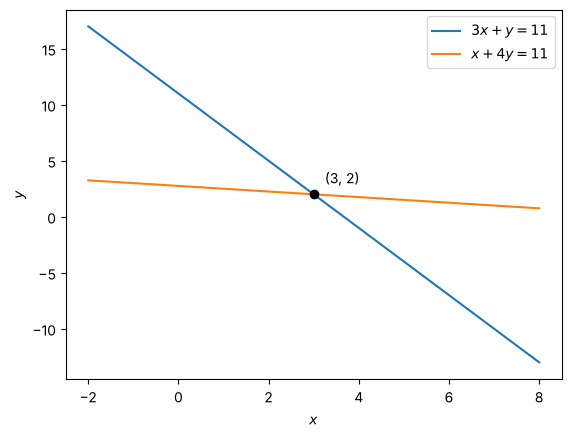

In [4]:
A = np.array([[3, 1],
              [1, 4]])
b = np.array([11, 11])
x = np.linalg.solve(A, b)

X = np.linspace(x[0] - 5, x[0] + 5, num=100)
Y1 = (b[0] - A[0,0]*X)/A[0,1]
Y2 = (b[1] - A[1,0]*X)/A[1,1]

plt.plot(X, Y1, label="$3x + y = 11$")
plt.plot(X, Y2, label="$x + 4y = 11$")
plt.plot(x[0], x[1], "ko")
plt.annotate("(3, 2)", (x[0], x[1]), textcoords="offset points", xytext=(8, 8))
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.show()

## Exercise 5: Desmos

On [desmos.com/calculator](https://www.desmos.com/calculator) type `3x+y=11` and `x+4y=11` on two lines.
Click the crossing point: Desmos labels it $(3, 2)$, the same as Exercise 4.

## Exercise 6: the feasible region

* $x + y = 2$ passes through $(2, 0)$ and $(0, 2)$; the region $x + y \le 2$ is below it.
* $x + 3y = 3$ passes through $(3, 0)$ and $(0, 1)$; the region $x + 3y \le 3$ is below it.
* $x \ge 0$ and $y \ge 0$ keep us in the first quadrant.

The two lines meet where $x + y = 2$ and $x + 3y = 3$: subtracting gives $2y = 1$, so $y = 0.5$ and $x = 1.5$.

The feasible region is the quadrilateral with corners $(0, 0)$, $(2, 0)$, $(1.5, 0.5)$ and $(0, 1)$.
In Desmos, type the four inequalities (`x+y<=2`, `x+3y<=3`, `x>=0`, `y>=0`); the region where all
four shadings overlap is this shape. The same picture in Python:

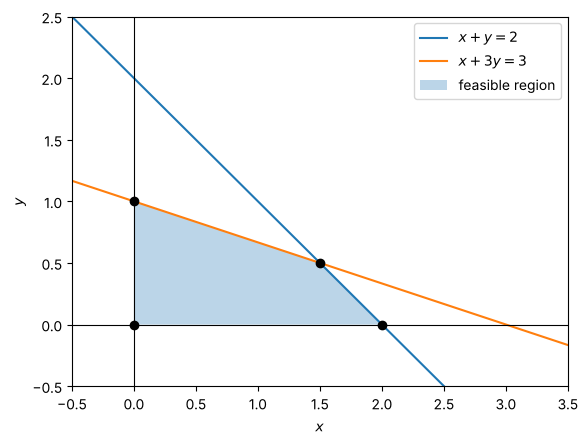

In [5]:
X = np.linspace(-0.5, 3.5, 100)
plt.plot(X, 2 - X, label="$x + y = 2$")
plt.plot(X, (3 - X)/3, label="$x + 3y = 3$")
plt.axhline(0, color="k", lw=0.8)
plt.axvline(0, color="k", lw=0.8)

corners = np.array([[0, 0], [2, 0], [1.5, 0.5], [0, 1]])
plt.fill(corners[:, 0], corners[:, 1], alpha=0.3, label="feasible region")
plt.plot(corners[:, 0], corners[:, 1], "ko")

plt.xlim(-0.5, 3.5)
plt.ylim(-0.5, 2.5)
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.show()

## Exercise 7: a 3 × 3 system

$
\mathbf{A} = \begin{pmatrix} 2 & 3 & -2 \\ 1 & -2 & 4 \\ 2 & -3 & 1 \end{pmatrix},
\qquad
\mathbf{x} = \begin{pmatrix} x \\ y \\ z \end{pmatrix},
\qquad
\mathbf{b} = \begin{pmatrix} 3 \\ 0 \\ 1 \end{pmatrix}
$

$\det \mathbf{A} = 39 \ne 0$, so there is exactly one solution:

$x = \frac{38}{39} \approx 0.974, \quad y = \frac{11}{39} \approx 0.282, \quad z = -\frac{4}{39} \approx -0.103$

The answer is not a whole number, so check it by substituting it back: $\mathbf{A}\mathbf{x}$ should give $\mathbf{b}$.

In [6]:
A = np.array([[2,  3, -2],
              [1, -2,  4],
              [2, -3,  1]])
b = np.array([3, 0, 1])

x = np.dot(np.linalg.inv(A), b)
print("det(A) =", round(np.linalg.det(A), 10))
print("x, y, z =", np.round(x, 3))
print("x, y, z times 39 =", np.round(x * 39, 10))   # 38, 11, -4
print("Check A @ x =", np.round(A @ x, 10))           # should be [3, 0, 1]

det(A) = 39.0
x, y, z = [ 0.974  0.282 -0.103]
x, y, z times 39 = [38. 11. -4.]
Check A @ x = [3. 0. 1.]


## Exercise 8: the three planes

The tutorial's 3D code with `A` and `b` changed to Exercise 7. The three planes meet at the black point. Change `view_init` to rotate the plot.

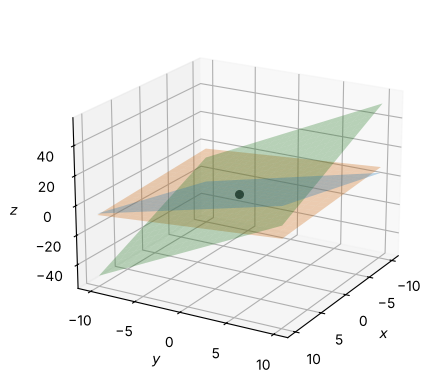

In [7]:
A = np.array([[2,  3, -2],
              [1, -2,  4],
              [2, -3,  1]])
b = np.array([3, 0, 1])
x = np.linalg.solve(A, b)

X = np.linspace(-10, 10, num=20)
Y = np.linspace(-10, 10, num=20)
xv, yv = np.meshgrid(X, Y)

# each equation solved for z (the z coefficients -2, 4 and 1 are not zero)
z1 = (b[0] - A[0,0]*xv - A[0,1]*yv)/A[0,2]
z2 = (b[1] - A[1,0]*xv - A[1,1]*yv)/A[1,2]
z3 = (b[2] - A[2,0]*xv - A[2,1]*yv)/A[2,2]

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.view_init(20, 30)
ax.plot_surface(xv, yv, z1, alpha=0.3)
ax.plot_surface(xv, yv, z2, alpha=0.3)
ax.plot_surface(xv, yv, z3, alpha=0.3)
ax.scatter(x[0], x[1], x[2], c="k", s=30)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_zlabel("$z$")
plt.show()